## Data Exploration & EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import pandas as pd


columns = (
    ["unit", "cycle", "set1", "set2", "set3"]
    + [f"s{i}" for i in range(1, 22)]
)

train = pd.read_csv("E:\\Predicting Jet Engine Failure\\data\\Raw Data\\train_FD001.txt", sep=r"\s+", header=None, names=columns)

test = pd.read_csv("E:\\Predicting Jet Engine Failure\\data\\Raw Data\\test_FD001.txt", sep=r"\s+", header=None, names=columns)



# NASA C-MAPSS FD001 Dataset: Data Dictionary

## 1. Dataset Overview

| Property | Description |
|---|---|
| Dataset name | NASA C-MAPSS Turbofan Engine Degradation Dataset |
| Subset | FD001 |
| Training engines | 100 |
| Test engines | 100 |
| Number of input features | 26 (3 operating settings + 21 sensors + unit ID + cycle) |
| Operating conditions | One operating condition category |
| Fault modes | One simulated fault mode |
| Training data | Engine run-to-failure trajectories |
| Test data | Engine trajectories ending before failure |
| Prediction target | Remaining Useful Life (RUL), measured in cycles |
| RUL cap | 125 cycles for training targets in this project |

## 2. Engine Identification and Time Features

| Feature | Type | Description | Example | Role in Project |
|---|---|---|---|---|
| `unit` | Integer | Unique identifier assigned to each engine | 1 | Groups records belonging to the same engine |
| `cycle` | Integer | Operating cycle number recorded for an engine | 50 | Represents the engine's observed operating history |

## 3. Operating Settings

| Feature | Type | Description | Example | Role in Project |
|---|---|---|---|---|
| `set1` | Float | First simulated operating setting, associated with altitude | -0.0007 | Helps characterize operating conditions |
| `set2` | Float | Second simulated operating setting, associated with Mach number | -0.0004 | Helps characterize operating conditions |
| `set3` | Float | Third simulated operating setting, associated with throttle resolver angle | 100.0 | Helps characterize operating conditions |

Note: The three operating settings describe the conditions under which the engine operates. They are not sensor measurements. Their numerical values are simulation inputs.

## 4. Sensor Measurements

The dataset contains 21 sensor channels. The table below describes their column identifiers. Exact physical interpretations and units should be taken from NASA's dataset documentation rather than inferred from the column names alone.

| Feature | Type | Description | Role in Project |
|---|---|---|---|
| `s1` | Float | Sensor measurement channel 1 | Candidate degradation feature |
| `s2` | Float | Sensor measurement channel 2 | Candidate degradation feature |
| `s3` | Float | Sensor measurement channel 3 | Candidate degradation feature |
| `s4` | Float | Sensor measurement channel 4 | Candidate degradation feature |
| `s5` | Float | Sensor measurement channel 5 | Candidate degradation feature |
| `s6` | Float | Sensor measurement channel 6 | Candidate degradation feature |
| `s7` | Float | Sensor measurement channel 7 | Candidate degradation feature |
| `s8` | Float | Sensor measurement channel 8 | Candidate degradation feature |
| `s9` | Float | Sensor measurement channel 9 | Candidate degradation feature |
| `s10` | Float | Sensor measurement channel 10 | Candidate degradation feature |
| `s11` | Float | Sensor measurement channel 11 | Candidate degradation feature |
| `s12` | Float | Sensor measurement channel 12 | Candidate degradation feature |
| `s13` | Float | Sensor measurement channel 13 | Candidate degradation feature |
| `s14` | Float | Sensor measurement channel 14 | Candidate degradation feature |
| `s15` | Float | Sensor measurement channel 15 | Candidate degradation feature |
| `s16` | Float | Sensor measurement channel 16 | Candidate degradation feature |
| `s17` | Float | Sensor measurement channel 17 | Candidate degradation feature |
| `s18` | Float | Sensor measurement channel 18 | Candidate degradation feature |
| `s19` | Float | Sensor measurement channel 19 | Candidate degradation feature |
| `s20` | Float | Sensor measurement channel 20 | Candidate degradation feature |
| `s21` | Float | Sensor measurement channel 21 | Candidate degradation feature |

## 5. Target Feature: Remaining Useful Life (RUL)

| Feature | Type | Description | Calculation |
|---|---|---|---|
| `RUL` | Integer | Number of operating cycles remaining before simulated failure | Last observed training cycle for the engine minus the current cycle |
| `RUL_capped` | Integer | RUL limited to a maximum of 125 cycles | Minimum of calculated RUL and 125 |

Example:

| unit | cycle | Last Cycle | Actual RUL | Capped RUL |
|---|---:|---:|---:|---:|
| 1 | 100 | 200 | 100 | 100 |
| 1 | 150 | 200 | 50 | 50 |
| 1 | 190 | 200 | 10 | 10 |
| 2 | 50 | 300 | 250 | 125 |

The training dataset contains complete engine lifetimes, so its RUL targets can be calculated directly. The test dataset does not contain the failure cycle for each engine. The provided `RUL_FD001.txt` file supplies the actual remaining cycles at the final observed test cycle.

## 6. Engineered Features

These features will be created during feature engineering. They are not present in the original text files.

| Feature Type | Example Column | Description | Purpose |
|---|---|---|---|
| Rolling mean | `s7_mean_15` | Mean of sensor `s7` over the latest 15 cycles | Smooths short-term fluctuations |
| Rolling standard deviation | `s7_std_15` | Standard deviation of sensor `s7` over the latest 15 cycles | Measures recent sensor variability |
| Rolling mean | `s11_mean_15` | Mean of sensor `s11` over the latest 15 cycles | Captures recent sensor behavior |
| Rolling standard deviation | `s11_std_15` | Standard deviation of sensor `s11` over the latest 15 cycles | Captures changes in variability |

Rolling features must be calculated separately for each engine and using only current and past observations. This avoids incorporating future measurements into a prediction.

## 7. Dataset Files

| File | Contents | Usage |
|---|---|---|
| `train_FD001.txt` | Training engine histories through failure | Training and validation |
| `test_FD001.txt` | Partial histories for test engines | Final model evaluation |
| `RUL_FD001.txt` | Actual remaining cycles at the final observed cycle of each test engine | Comparing predictions with ground truth |

## 8. Important Data Handling Rules

1. Calculate training RUL separately for each `unit`.
2. Cap training RUL at 125 cycles for this project.
3. Plot sensor measurements over cycles to identify constant or low-variation sensors.
4. Use training data to select features and avoid leakage from the test set.
5. Split training and validation data by engine, not by individual rows.
6. For official test evaluation, predict RUL only at each test engine's final observed cycle.
7. Compare predictions with `RUL_FD001.txt` and report RMSE in cycles.
8. Treat maintenance alerts as experimental predictions, not certified aviation safety decisions.

In [3]:
test.head()

,unit,cycle,set1,set2,set3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [4]:
train.head(5)

,unit,cycle,set1,set2,set3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## Why do we cap RUL at 125 cycles?
We cap Remaining Useful Life (RUL) at 125 because early in an engine's life, sensor readings may look similar even when the actual remaining lifetimes differ significantly.
How does it help?
- Reduces noise in the training targets.
- Helps the model focus on meaningful engine degradation patterns.
- Improves its ability to predict remaining cycles when an engine approaches failure.

In simple terms: Instead of predicting exact lifetimes far into the future, we focus the model on the period when sensor data becomes more useful for predicting engine failure

In [5]:
train['unit'].nunique()

100

In [6]:
# target: cycles left before failure, capped at 125

last_cycle = train.groupby("unit")["cycle"].transform("max")

train["RUL"] = (last_cycle - train["cycle"]).clip(upper=125)

In [7]:
train.head(5)

,unit,cycle,set1,set2,set3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,125
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,125
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,125
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,125
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,125


In [8]:
train.shape

(20631, 27)

In [9]:
train["unit"].nunique() , test["unit"].nunique()

(100, 100)

In [10]:
train.describe()

,unit,cycle,set1,set2,set3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705,86.829286
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251,41.673699
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200,0.000000
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800,51.000000
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900,103.000000
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800,125.000000
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400,125.000000


In [11]:
for col in train.columns:
    if train[col].isnull().any():
        print(f"{col} has missing values")
    else:
        print(f"{col} has no missing values")

unit has no missing values
cycle has no missing values
set1 has no missing values
set2 has no missing values
set3 has no missing values
s1 has no missing values
s2 has no missing values
s3 has no missing values
s4 has no missing values
s5 has no missing values
s6 has no missing values
s7 has no missing values
s8 has no missing values
s9 has no missing values
s10 has no missing values
s11 has no missing values
s12 has no missing values
s13 has no missing values
s14 has no missing values
s15 has no missing values
s16 has no missing values
s17 has no missing values
s18 has no missing values
s19 has no missing values
s20 has no missing values
s21 has no missing values
RUL has no missing values


## Explore the Sensors

In [12]:
sensors = [f"s{i}" for i in range(1, 22)]

Sensor standard deviations:
s1     0.000000e+00
s10    0.000000e+00
s19    0.000000e+00
s18    0.000000e+00
s16    3.469531e-18
s5     5.329200e-15
s6     1.388985e-03
s15    3.750504e-02
s8     7.098548e-02
s13    7.191892e-02
s21    1.082509e-01
s20    1.807464e-01
s11    2.670874e-01
s2     5.000533e-01
s12    7.375534e-01
s7     8.850923e-01
s17    1.548763e+00
s3     6.131150e+00
s4     9.000605e+00
s14    1.907618e+01
s9     2.208288e+01
dtype: float64

Sensors with almost zero variation:
['s1', 's5', 's10', 's16', 's18', 's19']


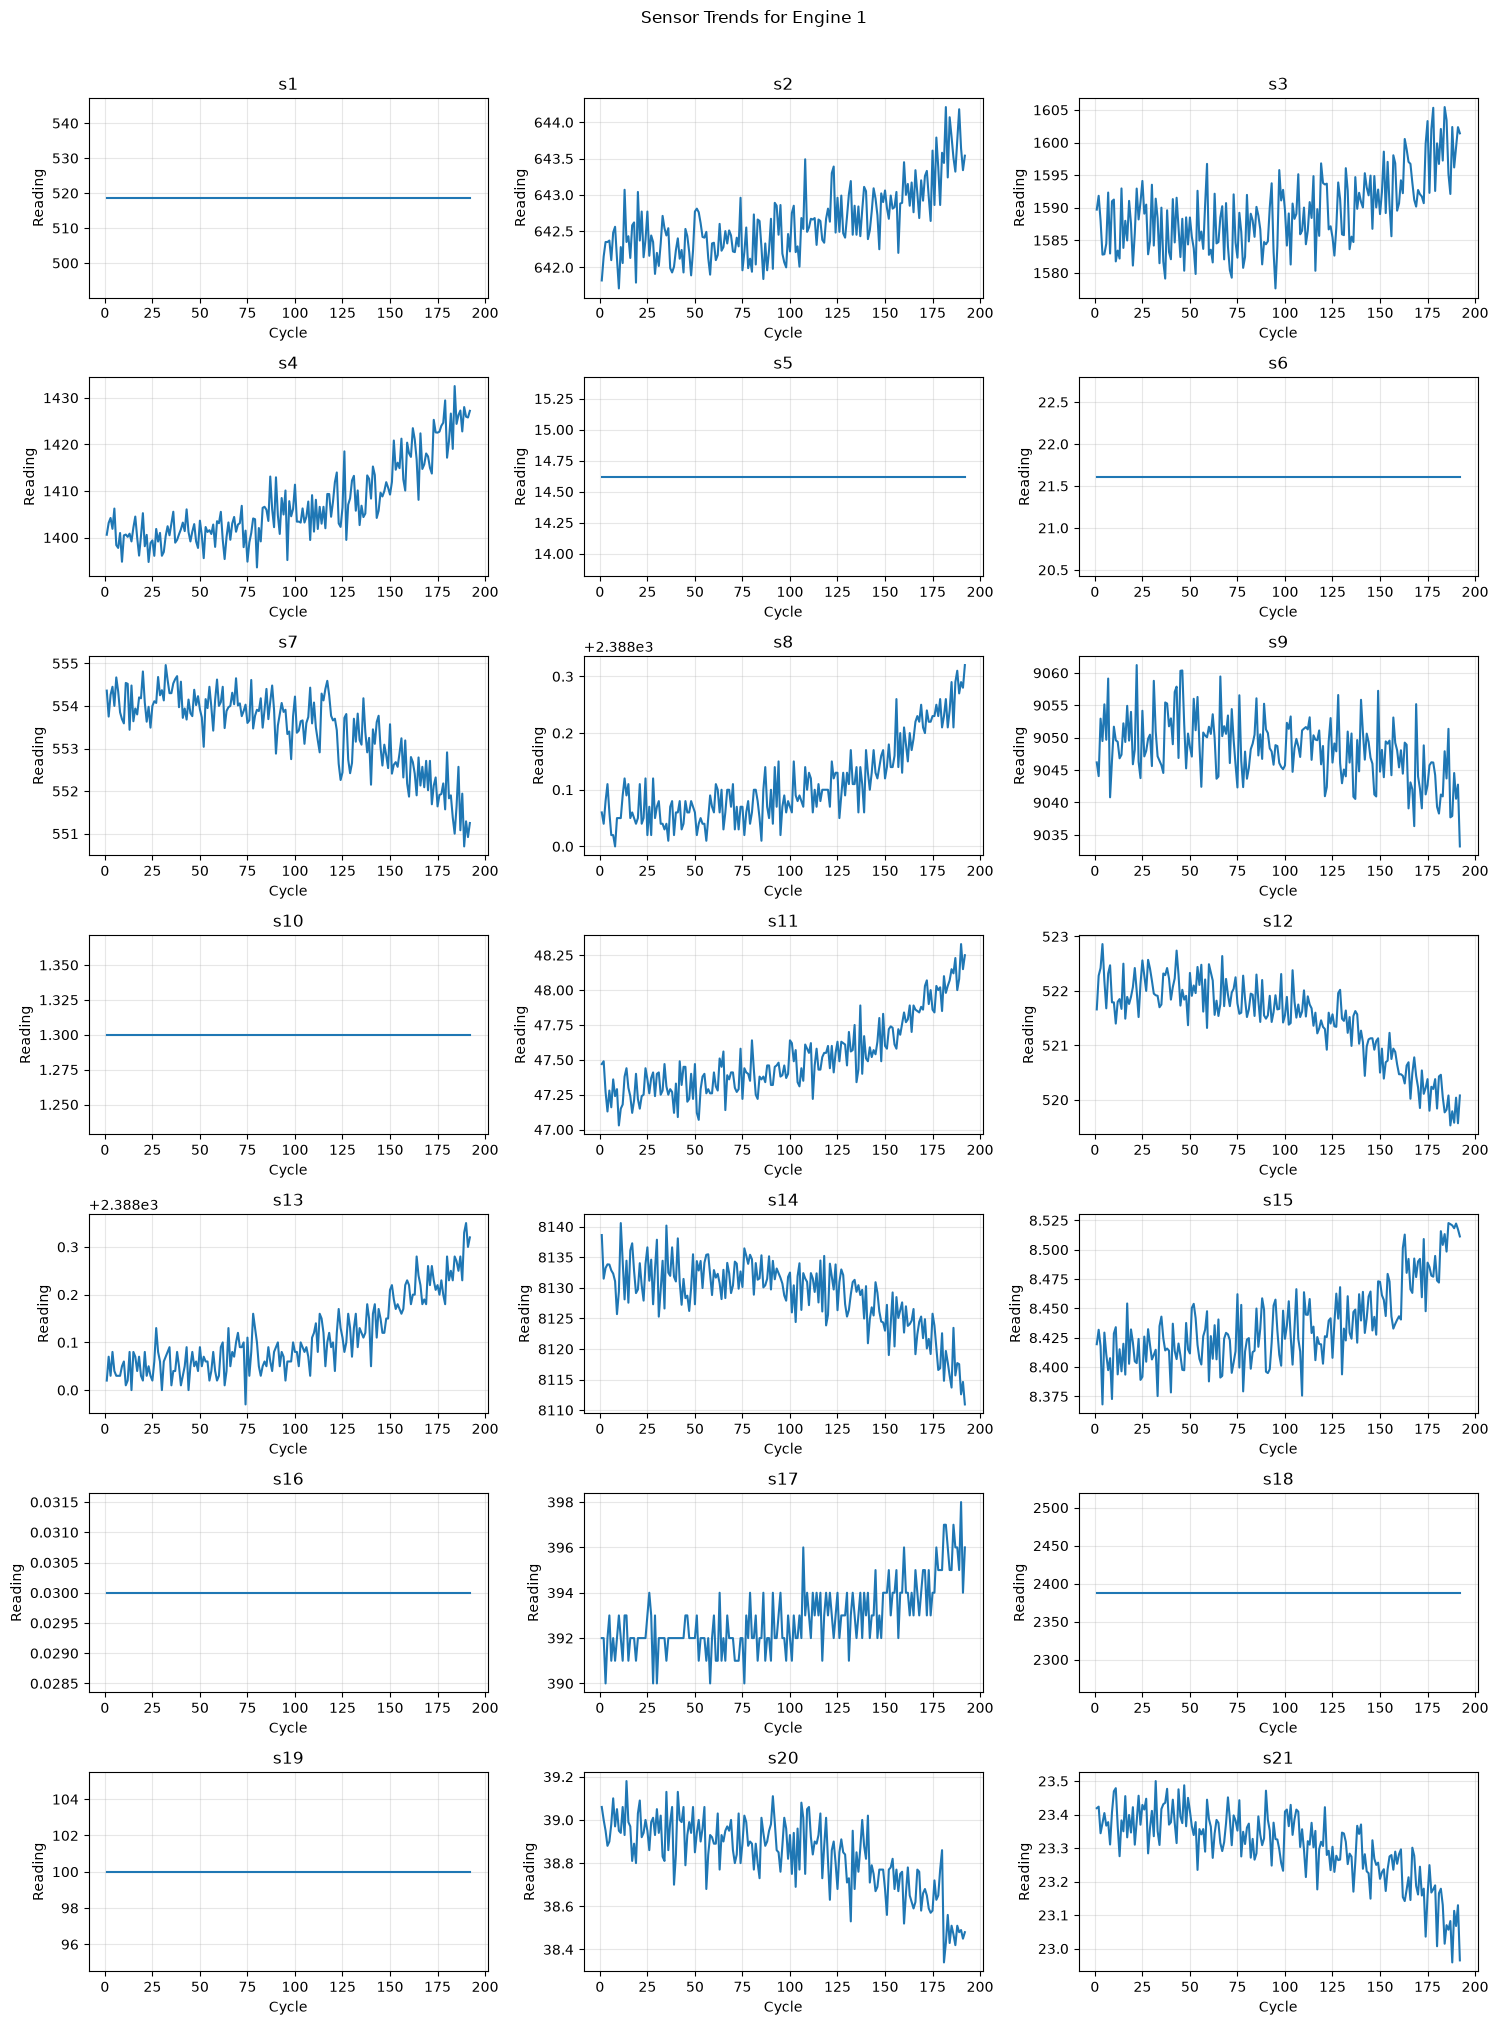

In [13]:
sensors = [f"s{i}" for i in range(1, 22)]

# Check variation across all training rows
sensor_std = train[sensors].std()

print("Sensor standard deviations:")
print(sensor_std.sort_values())

print("\nSensors with almost zero variation:")
print(sensor_std[sensor_std < 1e-3].index.tolist())

# Select one engine to visualize
engine_id = 1
engine = train[train["unit"] == engine_id].sort_values("cycle")

# Plot all 21 sensors
fig, axes = plt.subplots(7, 3, figsize=(15, 20))
axes = axes.flatten()

for i, sensor in enumerate(sensors):
    axes[i].plot(engine["cycle"], engine[sensor])
    axes[i].set_title(sensor)
    axes[i].set_xlabel("Cycle")
    axes[i].set_ylabel("Reading")
    axes[i].grid(True, alpha=0.3)

plt.suptitle(f"Sensor Trends for Engine {engine_id}", y=1.01)
plt.tight_layout()
plt.show()


In [14]:
train[sensors].describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
s1,518.670000,0.000000e+00,518.6700,518.6700
s2,642.680934,5.000533e-01,641.2100,644.5300
s3,1590.523119,6.131150e+00,1571.0400,1616.9100
s4,1408.933782,9.000605e+00,1382.2500,1441.4900
s5,14.620000,5.329200e-15,14.6200,14.6200
s6,21.609803,1.388985e-03,21.6000,21.6100
s7,553.367711,8.850923e-01,549.8500,556.0600
s8,2388.096652,7.098548e-02,2387.9000,2388.5600
s9,9065.242941,2.208288e+01,9021.7300,9244.5900
s10,1.300000,0.000000e+00,1.3000,1.3000


In [15]:
train[sensors].corrwith(train["RUL"]).sort_values(ascending=False)

e:\Python Program Files\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
e:\Python Program Files\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


s12    7.488699e-01
s7     7.330210e-01
s21    7.073341e-01
s20    7.046256e-01
s16    8.981235e-16
s5    -4.986049e-16
s6    -1.082888e-01
s14   -3.697526e-01
s9    -4.621509e-01
s13   -6.240343e-01
s8    -6.245680e-01
s3    -6.550304e-01
s2    -6.784583e-01
s17   -6.808295e-01
s15   -7.208585e-01
s4    -7.571567e-01
s11   -7.752298e-01
s1              NaN
s10             NaN
s18             NaN
s19             NaN
dtype: float64

In [16]:
nan_sensors = ["s1", "s10", "s18", "s19"]

print("Standard deviation:")
print(train[nan_sensors].var())

print("\nNumber of unique values:")
print(train[nan_sensors].nunique())

Standard deviation:
s1     0.0
s10    0.0
s18    0.0
s19    0.0
dtype: float64

Number of unique values:
s1     1
s10    1
s18    1
s19    1
dtype: int64


## Feature Engineering

In [17]:
final_sensors = [s for s in sensors if s not in nan_sensors]

In [18]:
# Sort by engine and cycle
train_df = train.sort_values(["unit", "cycle"]).copy()

In [19]:
train_df.head(5)

,unit,cycle,set1,set2,set3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,125
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,125
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,125
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,125
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,125


In [20]:
#Create rolling mean and standard deviation
rolling_window = 15

for sensor in final_sensors:
    train[f"{sensor}_mean_{rolling_window}"] = (
        train.groupby("unit")[sensor]
        .transform(
            lambda x: x.rolling(
                window=rolling_window, min_periods=1
            ).mean()
        )
    )

    train[f"{sensor}_std_{rolling_window}"] = (
        train.groupby("unit")[sensor]
        .transform(
            lambda x: x.rolling(
                window=rolling_window, min_periods=1
            ).std()
        )
        .fillna(0)
    )


In [21]:
train.shape

(20631, 61)

In [22]:
train.drop(columns=nan_sensors, inplace=True)

In [23]:
train.shape

(20631, 57)

In [24]:
train.head(5)

,unit,cycle,set1,set2,set3,s2,s3,s4,s5,s6,...,s15_mean_15,s15_std_15,s16_mean_15,s16_std_15,s17_mean_15,s17_std_15,s20_mean_15,s20_std_15,s21_mean_15,s21_std_15
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,14.62,21.61,...,8.419500,0.000000,0.03,0.0,392.000000,0.000000,39.060000,0.000000,23.419000,0.000000
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,14.62,21.61,...,8.425650,0.008697,0.03,0.0,392.000000,0.000000,39.030000,0.042426,23.421300,0.003253
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,14.62,21.61,...,8.423033,0.007640,0.03,0.0,391.333333,1.154701,39.003333,0.055076,23.395600,0.044573
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,14.62,21.61,...,8.409325,0.028117,0.03,0.0,391.500000,1.000000,38.972500,0.076322,23.390175,0.037977
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,14.62,21.61,...,8.413340,0.025953,0.03,0.0,391.800000,1.095445,38.958000,0.073621,23.393020,0.033498


In [25]:
train.to_csv("E:\\Predicting Jet Engine Failure\\data\\train_features.csv", index=False)